In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
X, y = make_moons(
    n_samples=1000,
    noise=0.20,
    random_state=42
)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("First 5 inputs:\n", X[:5])
print("First 5 labels:", y[:5])

Dataset shape: (1000, 2)
Labels shape: (1000,)
First 5 inputs:
 [[-0.11166654  0.52022374]
 [ 1.14264982 -0.34257734]
 [ 0.79555796 -0.01144231]
 [ 0.11182668 -0.55193153]
 [-0.81646618  0.54399604]]
First 5 labels: [1 1 1 1 0]


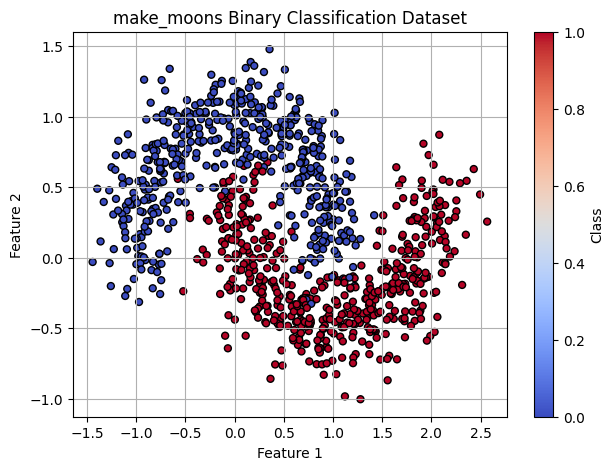

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black",
    s=25
)

plt.title("make_moons Binary Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.colorbar(label="Class")
plt.grid(True)
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled successfully!")
print("Testing data scaled successfully!")

Training data scaled successfully!
Testing data scaled successfully!


In [ ]:
ann_model = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    learning_rate_init=0.01,
    max_iter=1000,
    random_state=42,
    early_stopping=True
)

ann_model.fit(X_train_scaled, y_train)

print("ANN model training completed!")
print("Training iterations:", ann_model.n_iter_)

ANN model training completed!
Training iterations: 13


In [ ]:
y_pred = ann_model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Test Accuracy: 90.00%

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.82      0.89       100
           1       0.84      0.98      0.91       100

    accuracy                           0.90       200
   macro avg       0.91      0.90      0.90       200
weighted avg       0.91      0.90      0.90       200



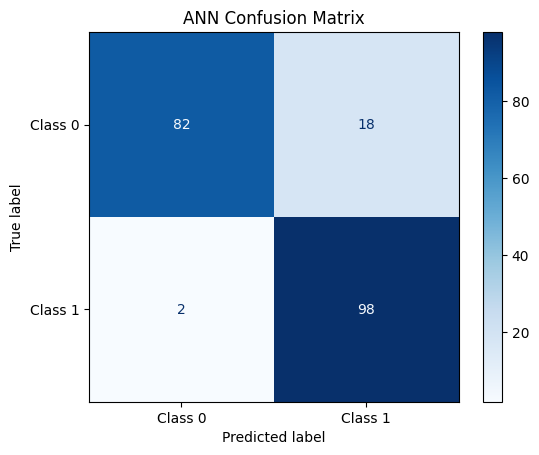

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    display_labels=["Class 0", "Class 1"]
)

plt.title("ANN Confusion Matrix")
plt.show()

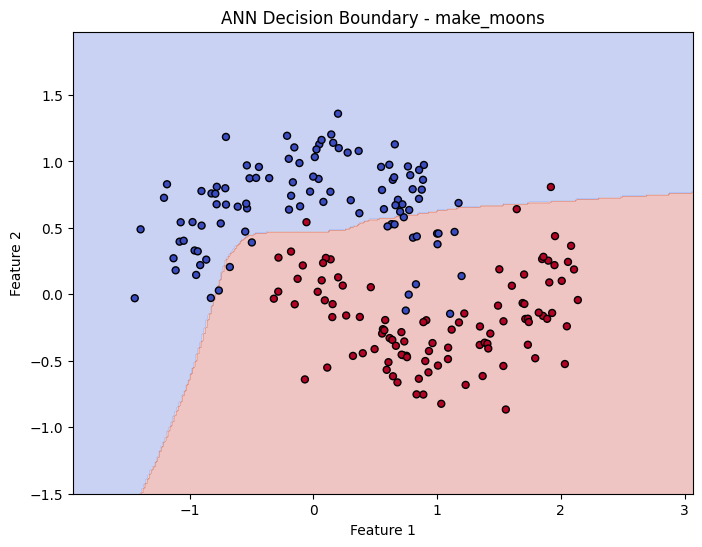

In [ ]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid)

Z = ann_model.predict(grid_scaled)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    cmap="coolwarm",
    edgecolors="black",
    s=25
)

plt.title("ANN Decision Boundary - make_moons")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
new_sample = np.array([[0.5, 0.5]])

new_sample_scaled = scaler.transform(new_sample)

prediction = ann_model.predict(new_sample_scaled)

print("Predicted Class:", prediction[0])

Predicted Class: 1
